# 01 · Exploratory data analysis

What is in the data, and what does it mean for the models? Each section asks a question, shows the raw data first and ends with key findings.

**Contents**
1. Data inventory
2. Labels
3. DICOM metadata
4. From slices to series
5. Labels along the series
6. Images

Needs:
- the Kaggle data in `raw_data_dir` (see `configs/paths.yaml`);
- the DICOM header table from `scripts/extract_dicom_headers.py`. Reading the headers of 1.94M files takes about four hours on a hard disk, so a script does it once and this notebook reads the result.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom

import pe.data.dicom  # noqa: F401  (sets pydicom to ignore the shortened UIDs)
from pe.paths import load_paths

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

paths = load_paths()
DATA_DIR, PROCESSED = paths["raw_data_dir"], paths["processed_data_dir"]
assert DATA_DIR.exists(), f"data not found: {DATA_DIR}"

IMAGE_LABEL = "pe_present_on_image"
LOCATION = ["rightsided_pe", "leftsided_pe", "central_pe"]
RVLV = ["rv_lv_ratio_gte_1", "rv_lv_ratio_lt_1"]
TYPE = ["chronic_pe", "acute_and_chronic_pe"]
SERIES_LABELS = ["negative_exam_for_pe", "indeterminate"] + LOCATION + RVLV + TYPE
INFO_LABELS = ["qa_motion", "qa_contrast", "flow_artifact", "true_filling_defect_not_pe"]  # in train.csv, not scored
SPLITS = ["train", "test"]
SYNTAX = {"1.2.840.10008.1.2": "implicit VR", "1.2.840.10008.1.2.1": "explicit VR",
          "1.2.840.10008.1.2.4.70": "JPEG lossless"}


def windowed(hu, center, width):
    # a CT window: HU in [center - width/2, center + width/2] mapped to [0, 1]
    return np.clip((hu - center + width / 2) / width, 0, 1)


train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
headers = pd.read_csv(PROCESSED / "dicom_headers.csv", dtype=str, keep_default_na=False)
headers["file_size"] = headers["file_size"].astype(int)
headers["syntax"] = headers["TransferSyntaxUID"].map(SYNTAX).fillna(headers["TransferSyntaxUID"])
headers["writer"] = headers["ImplementationVersionName"].replace("", "(none)")  # the software that wrote the file
headers["intercept"] = headers["RescaleIntercept"].astype(float)
print(f"train.csv: {len(train):,} rows | test.csv: {len(test):,} rows | header table: {len(headers):,} files, {headers.shape[1]} columns")

train.csv: 1,790,594 rows | test.csv: 146,853 rows | header table: 1,937,447 files, 48 columns


## 1. Data inventory

What did Kaggle give us? Files per split with their size, from the header table.

In [2]:
inventory = headers.groupby("split").agg(studies=("StudyInstanceUID", "nunique"), series=("SeriesInstanceUID", "nunique"),
                                         files=("path", "size"), size_gb=("file_size", lambda s: s.sum() / 1e9))
print({p.name: f"{p.stat().st_size / 1e6:.1f} MB" for p in sorted(DATA_DIR.glob("*.csv"))})
inventory.round(1)

{'sample_submission.csv': '2.7 MB', 'test.csv': '5.7 MB', 'train.csv': '120.0 MB'}


,studies,series,files,size_gb
split,,,,
test,650,650,146853,77.1
train,7279,7279,1790594,903.0


**Why:** file sizes are a cheap check before any pixel is read. A 512 × 512 image with 2 bytes per pixel is 524,288 bytes (512 KB) plus a small header; a compressed file is smaller.

In [3]:
sizes = (headers["file_size"] / 1024).groupby([headers["split"], headers["syntax"]]).describe(percentiles=[0.5])
sizes["count"] = sizes["count"].astype(int)
sizes[["count", "min", "50%", "max"]].round(1).rename(columns=lambda c: c if c == "count" else f"{c} (KB)")

count  min (KB)  50% (KB)  max (KB)
split syntax                                              
test  explicit VR       6841     512.8     512.8     513.1
      implicit VR     140012     512.7     512.7     512.9
train JPEG lossless   118719     146.1     206.1     255.6
      explicit VR     367213     512.8     513.1     513.2
      implicit VR    1304662     512.6     512.7     512.9

### 1.1 Images vs tables

**Question:** Does every file have its row in `train.csv` / `test.csv`, and the other way round? Do the paths and the table rows match the UIDs inside the files? Did every header read, and did every file pass the zip CRC check?

In [4]:
files = {s: set(headers.loc[headers["split"] == s, "SOPInstanceUID"]) for s in SPLITS}
tables = {"train": set(train["SOPInstanceUID"]), "test": set(test["SOPInstanceUID"])}
display(pd.DataFrame({s: {"files": len(files[s]), "table rows": len(tables[s]),
                          "files not in the table": len(files[s] - tables[s]),
                          "table rows without a file": len(tables[s] - files[s])} for s in SPLITS}).T)

expected = headers["split"] + "/" + headers["StudyInstanceUID"] + "/" + headers["SeriesInstanceUID"] + "/" + headers["SOPInstanceUID"] + ".dcm"
print("path = <split>/<Study>/<Series>/<SOP>.dcm for every file:", (headers["path"] == expected).all())
in_file = headers.set_index("SOPInstanceUID")[["StudyInstanceUID", "SeriesInstanceUID"]]
for name, t in (("train", train), ("test", test)):
    rows_ = t.set_index("SOPInstanceUID")[["StudyInstanceUID", "SeriesInstanceUID"]]
    print(f"{name}.csv: repeated SOPInstanceUIDs {t['SOPInstanceUID'].duplicated().sum()} | "
          f"Study and Series as in the file: {rows_.eq(in_file.loc[rows_.index]).all().all()}")
print("files in both splits:", len(files["train"] & files["test"]))
print("headers that could not be read:", (headers["read_error"] != "").sum() if "read_error" in headers else 0)
print("files whose CRC-32 differs from the zip:", (headers["crc_ok"] != "True").sum())

,files,table rows,files not in the table,table rows without a file
train,1790594,1790594,0,0
test,146853,146853,0,0


path = <split>/<Study>/<Series>/<SOP>.dcm for every file: True


train.csv: repeated SOPInstanceUIDs 0 | Study and Series as in the file: True
test.csv: repeated SOPInstanceUIDs 0 | Study and Series as in the file: True
files in both splits: 0
headers that could not be read: 0
files whose CRC-32 differs from the zip: 0


### 1.2 Key findings

- **1,937,447 DICOM files, 980 GB:** train 1,790,594 (903 GB), test 146,853 (77 GB).
- **Every study has exactly one series** (train 7,279, test 650). The competition calls it an *exam*; these notebooks say *series*.
- Files and table rows match one to one, and paths and rows match the UIDs inside the files.
- **Every header reads and every file passes the zip's CRC check,** so the download is intact. Pixels are decoded only for a sample (6.1).
- **6.6% of the train files (118,719) are JPEG lossless,** 146–256 KB. They need GDCM or pylibjpeg to decode. The visible test has none, but the hidden test may.
- All other files are 512.6–513.2 KB: a 512 × 512 image of 2 bytes per pixel plus the header.

## 2. Labels

### 2.1 Raw table

The first rows of `train.csv`, exactly as given (transposed): one row per slice, with the series labels repeated on every slice of the series.

In [5]:
train.head(3).T

,0,1,2
StudyInstanceUID,6897fa9de148,6897fa9de148,6897fa9de148
SeriesInstanceUID,2bfbb7fd2e8b,2bfbb7fd2e8b,2bfbb7fd2e8b
SOPInstanceUID,c0f3cb036d06,f57ffd3883b6,41220fda34a3
pe_present_on_image,0,0,0
negative_exam_for_pe,0,0,0
qa_motion,0,0,0
qa_contrast,0,0,0
flow_artifact,0,0,0
rv_lv_ratio_gte_1,0,0,0
rv_lv_ratio_lt_1,1,1,1


### 2.2 Consistency checks

**Question:** Are the series labels the same on every slice of a series, and do they follow the rules of the label hierarchy (00)?

In [6]:
series_cols = SERIES_LABELS + INFO_LABELS
print("series labels constant within every series:", (train.groupby("StudyInstanceUID")[series_cols].nunique() == 1).all().all())

per_series = train.groupby("StudyInstanceUID").agg(n_slices=(IMAGE_LABEL, "size"), n_pos=(IMAGE_LABEL, "sum"),
                                              **{c: (c, "first") for c in series_cols})
per_series["positive"] = (per_series["n_pos"] > 0).astype(int)
pos, indet = per_series["positive"] == 1, per_series["indeterminate"] == 1
checks = {
    "exactly one of negative, indeterminate, positive": per_series["negative_exam_for_pe"] + per_series["indeterminate"] + per_series["positive"] == 1,
    "positive: at least one location": ~pos | (per_series[LOCATION].sum(axis=1) >= 1),
    "positive: exactly one RV/LV label": ~pos | (per_series[RVLV].sum(axis=1) == 1),
    "positive: at most one type label": ~pos | (per_series[TYPE].sum(axis=1) <= 1),
    "negative and indeterminate: no location, RV/LV or type": pos | (per_series[LOCATION + RVLV + TYPE].sum(axis=1) == 0),
    "indeterminate: at least one QA label": ~indet | (per_series[["qa_motion", "qa_contrast"]].sum(axis=1) >= 1),
    "not indeterminate: no QA label": indet | (per_series[["qa_motion", "qa_contrast"]].sum(axis=1) == 0),
}
pd.DataFrame({"series that pass": {k: f"{v.sum():,} / {len(v):,}" for k, v in checks.items()}})

series labels constant within every series: True


,series that pass
"exactly one of negative, indeterminate, positive","7,279 / 7,279"
positive: at least one location,"7,279 / 7,279"
positive: exactly one RV/LV label,"7,279 / 7,279"
positive: at most one type label,"7,279 / 7,279"
"negative and indeterminate: no location, RV/LV or type","7,279 / 7,279"
indeterminate: at least one QA label,"7,279 / 7,279"
not indeterminate: no QA label,"7,279 / 7,279"


### 2.3 Prevalence

**Question:** How common is each label, among all series and among the positive ones?

In [7]:
kind = pd.Series(np.select([pos, indet], ["positive", "indeterminate"], "negative"), index=per_series.index)
print("series:", kind.value_counts().to_dict())
print(f"positive slices: {per_series['n_pos'].sum():,} of {per_series['n_slices'].sum():,} ({per_series['n_pos'].sum() / per_series['n_slices'].sum():.1%}); "
      f"all slices of positive series pooled: {per_series.loc[pos, 'n_pos'].sum() / per_series.loc[pos, 'n_slices'].sum():.1%}")
cols = SERIES_LABELS + INFO_LABELS
pd.DataFrame({"series": per_series[cols].sum(), "% of series": per_series[cols].mean() * 100,
              "% of positive series": per_series.loc[pos, cols].mean() * 100,
              "% of negative series": per_series.loc[kind == "negative", cols].mean() * 100}).round(1)

series: {'negative': 4911, 'positive': 2211, 'indeterminate': 157}
positive slices: 96,540 of 1,790,594 (5.4%); all slices of positive series pooled: 17.8%


,series,% of series,% of positive series,% of negative series
negative_exam_for_pe,4911,67.5,0.0,100.0
indeterminate,157,2.2,0.0,0.0
rightsided_pe,1875,25.8,84.8,0.0
leftsided_pe,1544,21.2,69.8,0.0
central_pe,401,5.5,18.1,0.0
rv_lv_ratio_gte_1,940,12.9,42.5,0.0
rv_lv_ratio_lt_1,1271,17.5,57.5,0.0
chronic_pe,292,4.0,13.2,0.0
acute_and_chronic_pe,145,2.0,6.6,0.0
qa_motion,63,0.9,0.0,0.0


Which locations come together, and how does central PE relate to RV/LV ≥ 1 (positive series only)?

In [8]:
p = per_series[pos]
combo = p[LOCATION].astype(str).agg("".join, axis=1).map(
    lambda s: " + ".join(n for n, b in zip(["right", "left", "central"], s) if b == "1"))
display(combo.value_counts().to_frame("series").assign(share=lambda d: (d["series"] / len(p) * 100).round(1)))
rv = {f"central_pe = {v}": p.loc[p["central_pe"] == v, "rv_lv_ratio_gte_1"].mean() * 100 for v in (0, 1)}
pd.Series(rv, name="RV/LV >= 1 (%)").round(1).to_frame()

,series,share
right + left,866,39.2
right,627,28.4
right + left + central,346,15.6
left,317,14.3
right + central,36,1.6
left + central,15,0.7
central,4,0.2


,RV/LV >= 1 (%)
central_pe = 0,36.2
central_pe = 1,71.1


### 2.4 Key findings

- **The labels pass every consistency check:** the series labels are the same on every slice of a series, and no series breaks a rule of the hierarchy. (This says nothing about whether the readers were right.)
- **4,911 negative series (67.5%), 157 indeterminate (2.2%), 2,211 positive (30.4%).** 5.4% of all slices are positive; pooled over the positive series, 17.8% of their slices.
- **Most PE is on both sides:** right + left 39.2%, right + left + central 15.6%. Central PE alone is almost absent (4 series).
- **RV/LV ≥ 1 is twice as common with central PE** (71.1% against 36.2%), so the two labels are worth predicting together.
- The QA labels (`qa_motion`, `qa_contrast`) appear only in indeterminate series (2.2): they are its reasons, and a possible extra target.
- **Rare labels:** acute and chronic 145 series, indeterminate 157, chronic 292, central 401. With 5 folds that is 29–80 per fold, so the folds must be stratified on them (02).

## 3. DICOM metadata

### 3.1 Raw header

One file as it is (`stop_before_pixels=True` reads only the header).

In [9]:
first = headers[headers["split"] == "train"].iloc[0]
print(pydicom.dcmread(DATA_DIR / first["path"], stop_before_pixels=True))

Dataset.file_meta -------------------------------
(0002,0010) Transfer Syntax UID                 UI: Implicit VR Little Endian
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0008) Image Type                          CS: "['ORIGINAL', 'PRIMARY', 'AXIAL']"
(0008,0016) SOP Class UID                       UI: 80e30f500244
(0008,0018) SOP Instance UID                    UI: 9445496b0916
(0008,0060) Modality                            CS: 'CT'
(0018,0050) Slice Thickness                     DS: '1.250000'
(0018,0060) KVP                                 DS: '100'
(0018,1120) Gantry/Detector Tilt                DS: '0.000000'
(0018,1130) Table Height                        DS: '167.500000'
(0018,1140) Rotation Direction                  CS: 'CW'
(0018,1151) X-Ray Tube Current                  IS: '398'
(0018,1152) Exposure                            IS: '5'
(0018,1210) Convolution Kernel                  SH: 'STANDARD'


### 3.2 Which fields carry information?

**Question:** How many distinct values does each field have, and is it constant within a series?

In [10]:
fields = [c for c in headers.columns if c not in ("path", "split", "file_size", "crc_ok", "read_error", "syntax", "writer", "intercept")]
n_unique = headers.groupby("StudyInstanceUID")[fields].nunique().max()
pd.DataFrame({
    "values (train)": headers.loc[headers["split"] == "train", fields].nunique(),
    "values (test)": headers.loc[headers["split"] == "test", fields].nunique(),
    "constant within each series": n_unique == 1,
    "example": headers[fields].iloc[0],
})

,values (train),values (test),constant within each series,example
FileMetaInformationGroupLength,13,9,False,204
FileMetaInformationVersion,2,2,True,b'\x00\x01'
MediaStorageSOPClassUID,2,2,True,1.2.840.10008.5.1.4.1.1.2
MediaStorageSOPInstanceUID,858938,50261,False,1.2.840.113654.2.70.1.112543990898997677342356...
TransferSyntaxUID,3,2,True,1.2.840.10008.1.2
ImplementationClassUID,3,3,True,1.2.826.0.1.3680043.8.498.1
ImplementationVersionName,5,4,True,PYDICOM 1.2.2
SpecificCharacterSet,11,7,True,ISO_IR 100
ImageType,5,7,False,"['ORIGINAL', 'PRIMARY', 'AXIAL']"
SOPClassUID,1,1,True,80e30f500244


### 3.3 Storage groups and sites

**Why:** each of the five institutions extracted and anonymised its own data, so the storage settings may tell the sites apart. If a group has a different share of positive series, the model can learn the site instead of the clot.

**Question:** Which storage settings occur together, how are they split between train and test, and does the share of positive series differ between them?

In [11]:
series_meta = headers.groupby("StudyInstanceUID").first()
series_meta["slices"] = headers.groupby("StudyInstanceUID").size()
GROUP = ["writer", "syntax", "BitsStored", "PixelRepresentation", "intercept"]
series_meta["positive"] = per_series["positive"].reindex(series_meta.index)
groups = series_meta.groupby(GROUP, dropna=False).agg(
    train=("split", lambda s: (s == "train").sum()), test=("split", lambda s: (s == "test").sum()),
    positive_pct=("positive", lambda s: s.mean() * 100), slices_median=("slices", "median"))
groups.sort_values("train", ascending=False).round(1)

train  test  positive_pct  slices_median
writer         syntax        BitsStored PixelRepresentation intercept                                          
(none)         implicit VR   16         1                   -1024.0     3586   414          25.3          231.0
PYDICOM 1.2.2  implicit VR   12         0                   -1024.0     1621   190          26.8          236.0
dcm4che-1.4.35 explicit VR   16         1                   -1024.0      867     2          72.9          238.0
dcm4che-1.4.37 JPEG lossless 16         1                   -1024.0      474     0           7.4          233.0
               explicit VR   16         1                   -1024.0      288     0           6.2          256.0
dcm4che-1.4.38 explicit VR   12         0                   -1024.0      207    42          47.8          151.0
(none)         implicit VR   16         1                    0.0         205     1          32.7          376.0
                             12         0                   -1024.0       28     1          50.0          279.0
dcm4che-1.4.35 explicit VR   12         0                   -1024.0        3     0         100.0          331.0

### 3.4 Geometry

**Question:** Image size, pixel spacing, slice thickness, orientation and patient position: what values occur, in train and in test?

In [12]:
def shares(col):
    # share (%) of series per value, train vs test
    return pd.crosstab(series_meta[col], series_meta["split"], normalize="columns").mul(100).round(1)


spacing = headers["PixelSpacing"].str.split("\\").str[0].astype(float)  # over all slices: both vary inside some series (4.3)
thickness = pd.to_numeric(headers["SliceThickness"], errors="coerce")
display(pd.DataFrame({"pixel spacing (mm)": spacing.groupby(headers["split"]).describe().T.stack(),
                      "slice thickness (mm)": thickness.groupby(headers["split"]).describe().T.stack()}).unstack().round(2))

iop = headers["ImageOrientationPatient"].str.split("\\", expand=True).astype(float).to_numpy()
normal = np.cross(iop[:, :3], iop[:, 3:])
headers["tilt"] = np.degrees(np.arccos(np.clip(np.abs(normal[:, 2]), 0, 1)))  # angle between the slice and an axial plane
tilted = headers.groupby("StudyInstanceUID")["tilt"].max()
print("series with a slice tilted more than 1 degree:", tilted.gt(1).groupby(series_meta["split"]).sum().to_dict())
print("tilt of those slices (degrees):", headers.loc[headers["tilt"] > 1, "tilt"].round(1).value_counts().to_dict())
headers["reversed"] = (iop[:, 0] < -0.9) | (iop[:, 4] < -0.9)  # rows or columns run the other way than usual
print("series with the image reversed:", headers.groupby("StudyInstanceUID")["reversed"].any().groupby(series_meta["split"]).sum().to_dict())
shares("PatientPosition")

pixel spacing (mm)             slice thickness (mm)            
split               test       train                 test       train
count          146853.00  1790594.00            146853.00  1790594.00
mean                0.68        0.68                 1.29        1.27
std                 0.08        0.08                 0.20        0.38
min                 0.47        0.30                 1.00        0.62
25%                 0.63        0.63                 1.25        1.25
50%                 0.68        0.68                 1.25        1.25
75%                 0.72        0.73                 1.25        1.25
max                 0.98        0.98                 3.00        5.00

series with a slice tilted more than 1 degree: {'test': 1, 'train': 0}
tilt of those slices (degrees): {3.1: 95, 86.9: 1}
series with the image reversed: {'test': 0, 'train': 1}


split,test,train
PatientPosition,,
FFP,0.0,0.0
FFS,92.0,95.9
HFS,8.0,4.1


### 3.5 Key findings

- **Every image is 512 × 512** (3.2). `RescaleSlope` is always 1 and `GantryDetectorTilt` always 0; their several values in 3.2 are only spellings ("1", "1.0", "1.000000"). Over all slices, pixel spacing is 0.30–0.98 mm (median 0.68) and slice thickness mostly 1.25 mm (0.62–5 mm).
- **Orientation:** one train series has its image reversed and must be flipped (02). One test series is tilted by 3° and holds one more slice in another plane (87°), so 02 sorts the slices along the slice normal rather than z. Most series are scanned feet first (FFS 96% of train, 92% of test).
- **The software that wrote the files splits the series into groups with very different positive rates:** dcm4che-1.4.35 72.9% (867 train series), dcm4che-1.4.37 6–7% (762), the other large groups 25–48%. These 9 groups probably reflect the 5 sites. A model can learn the site instead of the clot.
- **The test set is mixed differently:** the 1.4.35 and 1.4.37 groups are 22% of train but have 2 of the 650 test series. The folds are stratified on the group (02), and scores are checked per group.
- **The padding outside the scanned circle depends on the group** (6.1).

## 4. From slices to series

### 4.1 Slices per series

**Question:** How long is a series? This is the length of the sequence the series model reads.

,count,mean,std,min,5%,50%,95%,max
split,,,,,,,,
test,650.0,226.0,37.0,87.0,156.0,229.0,281.0,407.0
train,7279.0,246.0,74.0,63.0,173.0,234.0,389.0,1083.0


share of slices in series longer than 350: {'test': 0.5, 'train': 13.3}


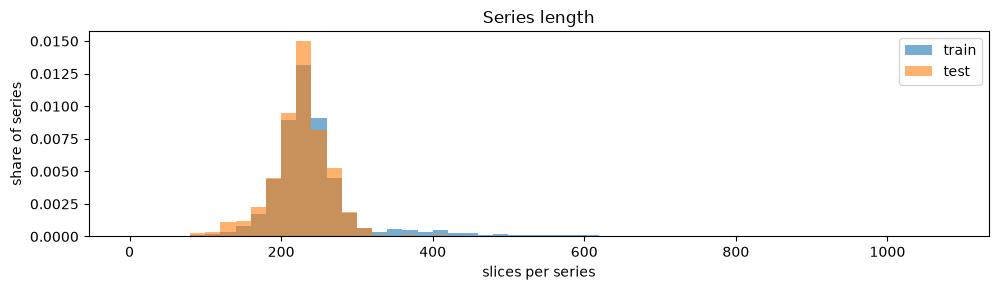

In [13]:
ipp = headers["ImagePositionPatient"].str.split("\\", expand=True).astype(float)
headers["z"] = ipp[2]
headers["instance"] = headers["InstanceNumber"].astype(int)
n = series_meta.groupby("split")["slices"]
display(n.describe(percentiles=[0.05, 0.5, 0.95]).round(0))
print("share of slices in series longer than 350:", (headers.groupby("split")["StudyInstanceUID"]
      .apply(lambda s: s.map(series_meta["slices"]).gt(350).mean() * 100)).round(1).to_dict())

fig, ax = plt.subplots(figsize=(10, 3))
for s in SPLITS:
    ax.hist(series_meta.loc[series_meta["split"] == s, "slices"], bins=np.arange(0, 1100, 20), alpha=0.6, density=True, label=s)
ax.set(xlabel="slices per series", ylabel="share of series", title="Series length")
ax.legend()
plt.tight_layout()

### 4.2 Slice order

`train.csv` does not say in which order the slices lie in the body. The order has to come from the header: the z coordinate of `ImagePositionPatient` or `InstanceNumber`.

**Question:** Do z and `InstanceNumber` give the same order? Is the CSV already in that order?

In [14]:
h = headers.sort_values(["StudyInstanceUID", "z"])
d_inst = h.groupby("StudyInstanceUID")["instance"].diff().dropna()
direction = d_inst.groupby(h["StudyInstanceUID"]).agg(up=lambda d: (d > 0).all(), down=lambda d: (d < 0).all())
print(f"series where InstanceNumber rises along z: {direction['up'].sum():,} | falls: {direction['down'].sum():,} | "
      f"neither: {(~direction['up'] & ~direction['down']).sum():,}")

order = train[["StudyInstanceUID", "SOPInstanceUID"]].merge(headers[["SOPInstanceUID", "z"]], on="SOPInstanceUID")
monotonic = order.groupby("StudyInstanceUID")["z"].agg(lambda z: z.is_monotonic_increasing or z.is_monotonic_decreasing)
print(f"train series whose CSV rows are already sorted by z: {monotonic.sum():,} of {len(monotonic):,}")

series where InstanceNumber rises along z: 2,181 | falls: 5,590 | neither: 158


train series whose CSV rows are already sorted by z: 0 of 7,279


### 4.3 Spacing, duplicates and gaps

**Question:** After sorting by z, are the slices evenly spaced? Are there slices at the same position, gaps, or two stacks in one series?

In [15]:
h["dz"] = h.groupby("StudyInstanceUID")["z"].diff()
gaps = h.groupby("StudyInstanceUID").agg(median_dz=("dz", "median"), max_dz=("dz", "max"),
                                         same_z=("dz", lambda d: (d.abs() < 0.01).sum()),
                                         frames=("FrameOfReferenceUID", "nunique"), series_numbers=("SeriesNumber", "nunique"),
                                         thicknesses=("SliceThickness", "nunique"), spacings=("PixelSpacing", "nunique"),
                                         not_original=("ImageType", lambda t: (~t.str.contains("ORIGINAL")).sum()))
gaps["split"] = series_meta["split"]
gaps["uneven"] = gaps["max_dz"] > 1.5 * gaps["median_dz"]
display(gaps.groupby("split")["median_dz"].describe(percentiles=[0.05, 0.5, 0.95]).round(2))
pd.DataFrame({
    "series with slices at the same z": gaps.groupby("split")["same_z"].apply(lambda s: (s > 0).sum()),
    "series with a gap > 1.5 x median spacing": gaps.groupby("split")["uneven"].sum(),
    "series with several FrameOfReferenceUIDs": gaps.groupby("split")["frames"].apply(lambda s: (s > 1).sum()),
    "series with several SeriesNumbers": gaps.groupby("split")["series_numbers"].apply(lambda s: (s > 1).sum()),
    "series with several slice thicknesses": gaps.groupby("split")["thicknesses"].apply(lambda s: (s > 1).sum()),
    "series with several pixel spacings": gaps.groupby("split")["spacings"].apply(lambda s: (s > 1).sum()),
    "series with images not marked ORIGINAL in ImageType": gaps.groupby("split")["not_original"].apply(lambda s: (s > 0).sum()),
}).T

,count,mean,std,min,5%,50%,95%,max
split,,,,,,,,
test,650.0,1.31,0.25,0.8,1.25,1.25,2.00,3.0
train,7279.0,1.23,0.23,0.0,0.80,1.25,1.25,5.0


split,test,train
series with slices at the same z,0,30
series with a gap > 1.5 x median spacing,1,126
series with several FrameOfReferenceUIDs,0,0
series with several SeriesNumbers,0,0
series with several slice thicknesses,0,111
series with several pixel spacings,1,107
series with images not marked ORIGINAL in ImageType,1,0


### 4.4 Key findings

- **Train series have 63–1,083 slices (median 234), visible test series 87–407 (median 229).** 13.3% of the train slices are in series longer than 350, but only 0.5% in the visible test, whose spacing is more often wide (95th percentile 2.0 mm against 1.25 mm). The series model must handle such lengths, or the slices are resampled along z in mm.
- **The CSV order is never the body order, and `InstanceNumber` is not a safe key:** it falls along z in 5,590 series, rises in 2,181 and is mixed in 158 (30 of them have slices at the same z). The slices are sorted by `ImagePositionPatient` along the slice normal, which is z unless the series is tilted (02). With z rising, the first slice is the abdomen and the last one the neck (6.2).
- **Median spacing 1.25 mm, but some train series are irregular:** 30 have slices at the same z, 126 a gap, 111 several slice thicknesses and 107 several pixel spacings. Two of them hold every slice twice (median spacing 0), which also counts them as gaps. The visible test has 1–2 such series. How to handle them is decided in 02.

## 5. Labels along the series

The slice labels in z order (train only). Only positive series have positive slices.

### 5.1 How many slices are positive?

**Question:** How many positive slices does a positive series have ($m_i$), and what share of its slices ($q_i$, the slice weight of the metric)?

In [16]:
s = train[["StudyInstanceUID", "SOPInstanceUID", IMAGE_LABEL]].merge(headers[["SOPInstanceUID", "z"]], on="SOPInstanceUID")
s = s.sort_values(["StudyInstanceUID", "z"]).reset_index(drop=True)
s["k"] = s.groupby("StudyInstanceUID").cumcount()
s["n"] = s["StudyInstanceUID"].map(per_series["n_slices"])
s["position"] = s["k"] / (s["n"] - 1)  # 0 and 1 are the two ends of the series
s = s[s["StudyInstanceUID"].map(per_series["positive"]) == 1]

q = per_series.loc[pos, "n_pos"] / per_series.loc[pos, "n_slices"]
pd.DataFrame({"positive slices (m)": per_series.loc[pos, "n_pos"].describe(percentiles=[0.05, 0.5, 0.95]),
              "share of slices (q, %)": (q * 100).describe(percentiles=[0.05, 0.5, 0.95])}).round(1)

,positive slices (m),"share of slices (q, %)"
count,2211.0,2211.0
mean,43.7,18.2
std,35.8,14.1
min,1.0,0.2
5%,4.0,1.7
50%,34.0,14.4
95%,111.0,44.1
max,242.0,87.0


### 5.2 Are positive slices contiguous?

**Question:** Do the positive slices of a series form one block, or several? How often does a slice share the true label of the slice before it (positive series only)?

In [17]:
starts = (s[IMAGE_LABEL] == 1) & (s.groupby("StudyInstanceUID")[IMAGE_LABEL].shift(fill_value=0) == 0)
runs = starts.groupby(s["StudyInstanceUID"]).sum()
display(runs.value_counts().sort_index().head(8).to_frame("series").T)
prev = s.groupby("StudyInstanceUID")[IMAGE_LABEL].shift()
print(f"P(positive | slice before positive) = {s.loc[prev == 1, IMAGE_LABEL].mean():.3f} | "
      f"P(positive | slice before negative) = {s.loc[prev == 0, IMAGE_LABEL].mean():.3f}")

pe_present_on_image,1,2,3,4,5,6,7,8
series,1327,481,214,92,41,23,11,5


P(positive | slice before positive) = 0.958 | P(positive | slice before negative) = 0.009


### 5.3 Position in the series

**Question:** Where along the series are the positive slices? 0 and 1 are its two ends.

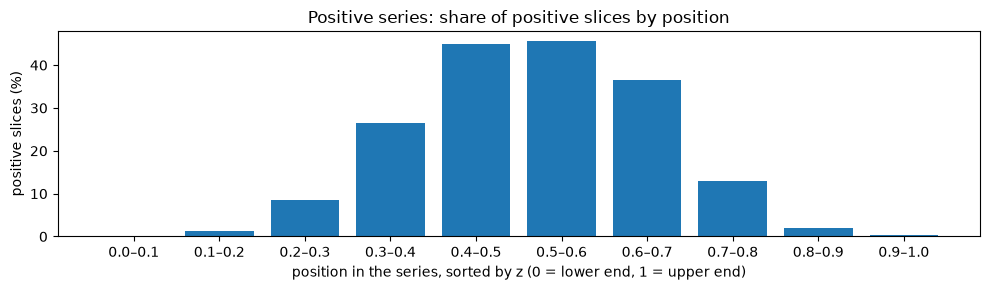

In [18]:
bins = pd.cut(s["position"], np.linspace(0, 1, 11), include_lowest=True)
share = s.groupby(bins, observed=True)[IMAGE_LABEL].mean() * 100
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(range(10), share.values)
ax.set(xticks=range(10), xticklabels=[f"{i / 10:.1f}–{(i + 1) / 10:.1f}" for i in range(10)],
       xlabel="position in the series, sorted by z (0 = lower end, 1 = upper end)", ylabel="positive slices (%)", title="Positive series: share of positive slices by position")
plt.tight_layout()

### 5.4 Key findings

- **A positive series has 1–242 positive slices (median 34): q is 14.4% at the median, 18.2% on average.** (The 17.8% of 2.3 pools all slices of positive series, so long series weigh more.)
- **Positive slices mostly form one block** (60% of series, 22% two blocks). Within positive series, a slice is positive in 95.8% of cases when the slice before is, and in 0.9% when it is not. These are true labels, not predictions, but they show that neighbouring slices are informative: for the slice input (2.5D) and for the series model.
- **PE sits in the middle of the series** (positions 0.3–0.7: lungs and heart). The two ends (abdomen, neck) almost never have it.

## 6. Images

A sample: up to 5 series per storage group and split (62 series), 5 slices each, evenly spaced along z.

### 6.1 From stored values to Hounsfield units

**Question:** Do the pixels decode in every storage group, and what HU range do they cover? What value fills the area outside the scanned circle?

In [19]:
sample = series_meta.sample(frac=1, random_state=0).groupby(GROUP + ["split"], dropna=False).head(5).reset_index()
rows = []
for _, e in sample.iterrows():
    sl = headers[headers["StudyInstanceUID"] == e["StudyInstanceUID"]].sort_values("z")
    for _, f in sl.iloc[np.linspace(0, len(sl) - 1, 5).astype(int)].iterrows():
        d = pydicom.dcmread(DATA_DIR / f["path"])
        hu = d.pixel_array.astype(np.float32) * float(d.RescaleSlope) + float(d.RescaleIntercept)
        counts, edges = np.histogram(hu, bins=np.arange(-1050, 1650, 100))  # 100 HU bins centred on -1000, -900, ...; values below -1050 left out
        rows.append({**{g: e[g] for g in GROUP}, "split": e["split"], "hu_min": hu.min(), "hu_max": hu.max(),
                     "below_-1100_pct": (hu < -1100).mean() * 100, "below_-1024_pct": (hu < -1024).mean() * 100,
                     "corner_hu": hu[0, 0],
                     "peak_hu": edges[counts.argmax()] + 50})
pixels = pd.DataFrame(rows)
print(f"{len(sample)} series, {len(pixels)} slices decoded")
pixels.groupby(GROUP, dropna=False).agg(slices=("hu_min", "size"), hu_min=("hu_min", "min"), corner_hu=("corner_hu", "median"),
                                        below_1100_pct=("below_-1100_pct", "mean"), below_1024_pct=("below_-1024_pct", "mean"),
                                        peak_hu=("peak_hu", "median"), hu_max=("hu_max", "max")).round(1)

62 series, 310 slices decoded


slices  hu_min  corner_hu  below_1100_pct  below_1024_pct  peak_hu   hu_max
writer         syntax        BitsStored PixelRepresentation intercept                                                                             
(none)         implicit VR   12         0                   -1024.0        30 -1024.0    -1024.0             0.0             0.0  -1000.0   3071.0
                             16         1                   -1024.0        50 -3024.0    -3024.0            21.3            21.3  -1000.0   3071.0
                                                             0.0           30 -2710.0    -2048.0            21.5            22.6   -100.0  10466.0
PYDICOM 1.2.2  implicit VR   12         0                   -1024.0        50 -1024.0    -1003.0             0.0             0.0  -1000.0   3071.0
dcm4che-1.4.35 explicit VR   12         0                   -1024.0        15 -1024.0    -1024.0             0.0             0.0  -1000.0   3071.0
                             16         1                   -1024.0        35 -3024.0    -3024.0            21.3            21.3  -1000.0   3071.0
dcm4che-1.4.37 JPEG lossless 16         1                   -1024.0        25 -3024.0    -3024.0            21.3            21.3   -100.0   3071.0
               explicit VR   16         1                   -1024.0        25 -3024.0    -3024.0            21.3            21.3   -900.0   3071.0
dcm4che-1.4.38 explicit VR   12         0                   -1024.0        50 -1024.0    -1024.0             0.0             0.0  -1000.0   3071.0

### 6.2 What a clot looks like

One positive series: slices along z, and one positive slice in three windows. A window maps an HU range to the gray scale: 100/700 for the contrast-filled arteries (PE), 40/400 for the mediastinum and −600/1500 for the lungs.

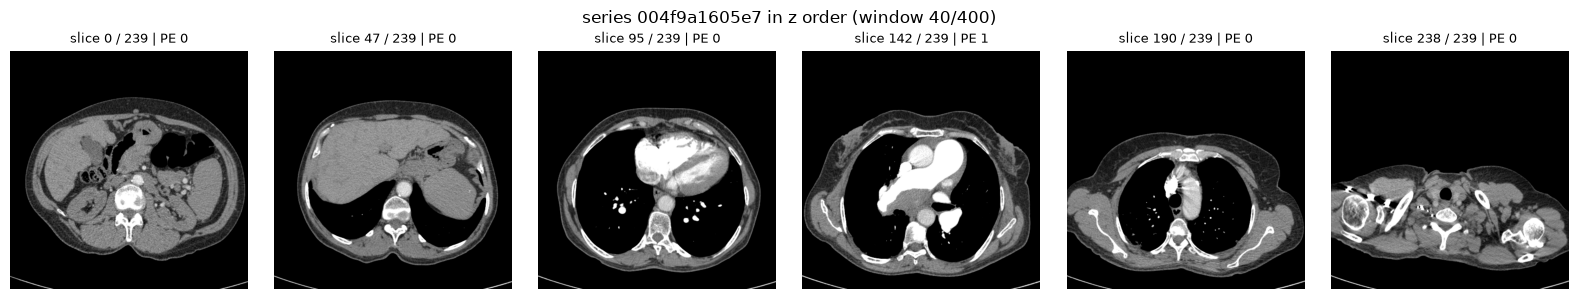

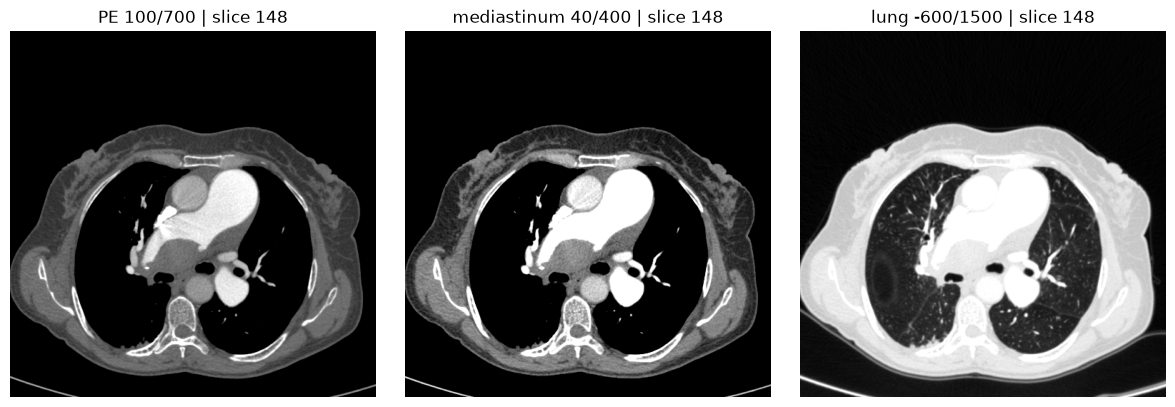

In [20]:
e = s.loc[s.groupby("StudyInstanceUID")[IMAGE_LABEL].transform("sum") >= 40, "StudyInstanceUID"].iloc[0]
sl = s[s["StudyInstanceUID"] == e].merge(headers[["SOPInstanceUID", "path"]], on="SOPInstanceUID")


def hu_of(path):
    d = pydicom.dcmread(DATA_DIR / path)
    return d.pixel_array.astype(np.float32) * float(d.RescaleSlope) + float(d.RescaleIntercept)


picks = sl.iloc[np.linspace(0, len(sl) - 1, 6).astype(int)]
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax, (_, r) in zip(axes, picks.iterrows()):
    ax.imshow(windowed(hu_of(r["path"]), 40, 400), cmap="gray")
    ax.set_title(f"slice {r['k']} / {r['n']} | PE {r[IMAGE_LABEL]}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"series {e} in z order (window 40/400)")
plt.tight_layout()

positive_slice = sl[sl[IMAGE_LABEL] == 1].iloc[len(sl[sl[IMAGE_LABEL] == 1]) // 2]
hu = hu_of(positive_slice["path"])
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, c, w) in zip(axes, [("PE 100/700", 100, 700), ("mediastinum 40/400", 40, 400), ("lung -600/1500", -600, 1500)]):
    ax.imshow(windowed(hu, c, w), cmap="gray")
    ax.set_title(f"{name} | slice {positive_slice['k']}")
    ax.axis("off")
plt.tight_layout()

### 6.3 Key findings

- **Every storage group decodes, the JPEG lossless one included, and gives plausible HU:** the most common value is air (−1000), lung (−900) or fat (−100).
- **In the 16-bit groups about 21% of the pixels are padding** outside the scanned circle, at −3024 (or −2048 and below in the intercept-0 group). The 12-bit groups have no value below −1024.
- **Unclipped, the padding would mark the group:** the lung window (−600/1500) starts at −1350, so −1024 shows dark gray (0.22) while −3024 shows black. Clipping HU to [−1024, 3071] before any window makes the padding the same in every group (02).
- **The intercept-0 group goes up to 10,466 HU** (metal), which the same clipping removes.
- **The contrast-filled arteries are brightest in the 100/700 and 40/400 windows,** where a clot shows as a dark gap inside them. Which windows the model gets is decided in 04.

## Summary

- **Data:** 1.94M files, 980 GB. Every header reads and every file matches the zip's CRC. 6.6% of train files are JPEG lossless.
- **Labels:** pass every consistency check. 30.4% of series and 5.4% of slices are positive. Rare labels (acute and chronic, indeterminate, chronic, central) need stratified folds.
- **Sites:** the file-writing software marks groups with 6% to 73% positive series, mixed differently in test. Folds are stratified on it; scores are checked per group.
- **Order:** slices are sorted along the slice normal (z), never by CSV order or `InstanceNumber`. Some train series have repeated positions, gaps, mixed thickness or a reversed image (02).
- **Signal:** positive slices form blocks in the middle of the series, so neighbouring slices are informative.
- **Pixels:** the padding differs by group and metal reaches 10,466 HU; HU are clipped to [−1024, 3071], which also makes the padding the same everywhere.

**Limits**
- Pixels were decoded for a sample of 62 series only (section 6).
- The storage groups stand in for the sites; the data does not name the sites.
- Train and test are compared on the 650 visible test series only; the 1,517 hidden ones are seen only by Kaggle.
- The train labels come from one reader, the test labels from three (00). Nothing here measures how much that changes the labels.